## Laplacian Visualization — result-20251217_122234-bunny.obj

In [17]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import trimesh
import igl
import plotly.graph_objects as go

workspace_path = os.path.dirname(os.path.dirname(os.path.abspath("__file__")))
print(workspace_path)

/path/to/shape-from-heat-conduction-and-shading


## Load OBJ

In [18]:
obj_path = os.path.join(workspace_path, 'results', 'optimized-res', 'result-20251217_122234-bunny.obj')

mesh = trimesh.load(obj_path, process=False)
verts_np = np.array(mesh.vertices, dtype=np.float64)
faces_np = np.array(mesh.faces, dtype=np.int32)

print(f"Vertices: {verts_np.shape}")
print(f"Faces:    {faces_np.shape}")

Vertices: (8955, 3)
Faces:    (17663, 3)


## Compute Laplacian

In [19]:
# Cotangent Laplacian matrix  (sparse, n_verts x n_verts)
L = igl.cotmatrix(verts_np, faces_np)

# Mean curvature normal:  H_vec[i] = (L @ V)[i]  (3D vector per vertex)
H_vec = L @ verts_np  # shape: (n_verts, 3)

# Scalar mean curvature magnitude
H_mag = np.linalg.norm(H_vec, axis=1)  # shape: (n_verts,)

# Gaussian curvature
K = igl.gaussian_curvature(verts_np, faces_np)  # shape: (n_verts,)

print(f"H_mag — min: {H_mag.min():.4f}, max: {H_mag.max():.4f}, mean: {H_mag.mean():.4f}")
print(f"K     — min: {K.min():.4f},    max: {K.max():.4f},    mean: {K.mean():.4f}")

H_mag — min: 0.0000, max: 0.0042, mean: 0.0002
K     — min: -0.2701,    max: 4.7301,    mean: 0.0867


## 3D Visualization — Mean Curvature (|LV|)

In [20]:
vmax = np.percentile(H_mag, 95)
H_clipped = np.clip(H_mag, 0, vmax)

fig = go.Figure(go.Mesh3d(
    x=verts_np[:, 0], y=verts_np[:, 1], z=verts_np[:, 2],
    i=faces_np[:, 0], j=faces_np[:, 1], k=faces_np[:, 2],
    intensity=H_clipped,
    colorscale='Turbo',
    colorbar=dict(title='|LV|'),
    showscale=True,
))
fig.update_layout(
    title='Mean Curvature magnitude |LV|',
    scene=dict(aspectmode='data'),
    width=800, height=700,
)
fig.show()

## 3D Visualization — Gaussian Curvature

In [21]:
k_abs_max = np.percentile(np.abs(K), 95)
K_clipped = np.clip(K, -k_abs_max, k_abs_max)

fig = go.Figure(go.Mesh3d(
    x=verts_np[:, 0], y=verts_np[:, 1], z=verts_np[:, 2],
    i=faces_np[:, 0], j=faces_np[:, 1], k=faces_np[:, 2],
    intensity=K_clipped,
    colorscale='RdBu',
    colorbar=dict(title='K'),
    showscale=True,
))
fig.update_layout(
    title='Gaussian Curvature K',
    scene=dict(aspectmode='data'),
    width=800, height=700,
)
fig.show()

## Cotangent Weight Distribution (per-vertex row-sum)

In [22]:
# Diagonal of L = negative sum of off-diagonal weights per vertex
L_diag = np.array(L.diagonal())  # shape: (n_verts,)

diag_abs_max = np.percentile(np.abs(L_diag), 95)
L_diag_clipped = np.clip(L_diag, -diag_abs_max, diag_abs_max)

fig = go.Figure(go.Mesh3d(
    x=verts_np[:, 0], y=verts_np[:, 1], z=verts_np[:, 2],
    i=faces_np[:, 0], j=faces_np[:, 1], k=faces_np[:, 2],
    intensity=L_diag_clipped,
    colorscale='Turbo',
    colorbar=dict(title='L diag'),
    showscale=True,
))
fig.update_layout(
    title='Cotangent Laplacian — diagonal (row weight sum)',
    scene=dict(aspectmode='data'),
    width=800, height=700,
)
fig.show()

## Histogram of curvature values

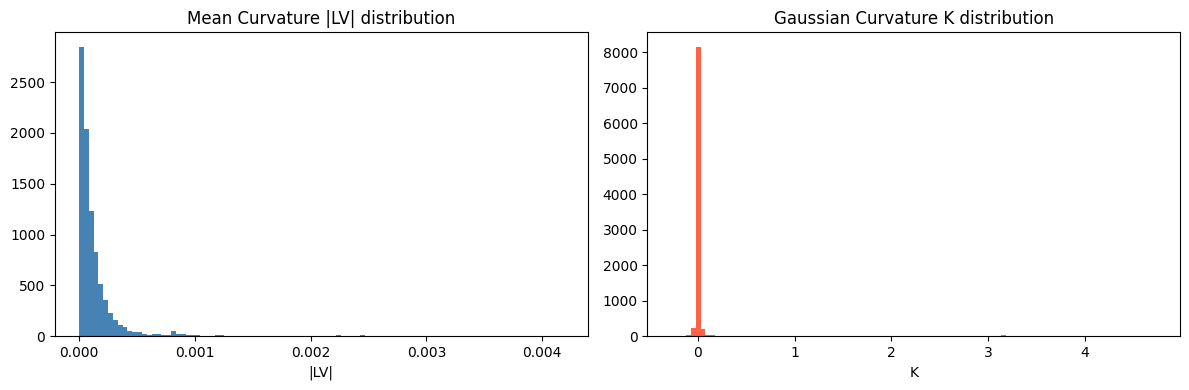

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(H_mag, bins=100, color='steelblue', edgecolor='none')
axes[0].set_title('Mean Curvature |LV| distribution')
axes[0].set_xlabel('|LV|')

axes[1].hist(K, bins=100, color='tomato', edgecolor='none')
axes[1].set_title('Gaussian Curvature K distribution')
axes[1].set_xlabel('K')

plt.tight_layout()
plt.show()

## 2D Projection — Gaussian Curvature (imshow)

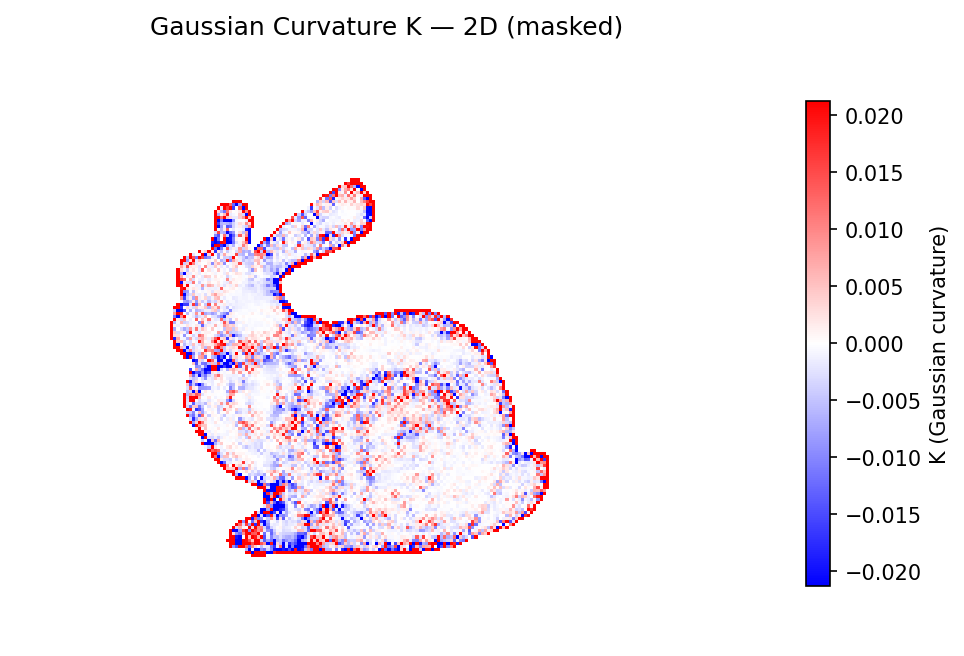

In [27]:
import pickle
import cv2

# Load vertex-to-pixel mapping and mask from optimization result
opti_pkl_path = os.path.join(workspace_path, 'DATA', 'obj_study_proc',
    'bunny-black-v81-incan-0-left-rad1-tlin0-2024-01-28_17-19-43_opti_results192x240-Delta10.pkl')
mask_pkl_path = os.path.join(workspace_path, 'DATA', 'obj_study_proc',
    'bunny-black-v81-incan-0-left-rad1-tlin0-2024-01-28_17-19-43_mask.pkl')

with open(opti_pkl_path, 'rb') as f:
    opti = pickle.load(f)
with open(mask_pkl_path, 'rb') as f:
    mask_dict = pickle.load(f)

# pixel_coords: (n_verts, 2) — [row, col] at 192x240 resolution
pixel_coords = opti['cat_corres_pixel_coords_init'].cpu().numpy().astype(int)

# Mask: (512, 640) -> resize to 192x240
mask_orig = mask_dict['mask']  # (512, 640), 0/1
mask_small = cv2.resize(mask_orig.astype(np.uint8), (240, 192),
                        interpolation=cv2.INTER_NEAREST).astype(bool)

img_h, img_w = 192, 240

# Paint K values at vertex pixel locations
K_img = np.full((img_h, img_w), np.nan)
for i, (r, c) in enumerate(pixel_coords):
    if 0 <= r < img_h and 0 <= c < img_w:
        K_img[r, c] = K[i]

# Fill sparse gaps inside the mask with nearest-neighbour interpolation
from scipy.ndimage import generic_filter

K_filled = K_img.copy()
for _ in range(8):
    nan_mask = np.isnan(K_filled) & mask_small
    if not nan_mask.any():
        break
    filled = generic_filter(K_filled, np.nanmean, size=3, mode='constant', cval=np.nan)
    K_filled[nan_mask] = filled[nan_mask]

# Apply mask — background -> NaN (rendered as white)
K_masked = np.where(mask_small, K_filled, np.nan)

abs_max = np.nanpercentile(np.abs(K_masked[~np.isnan(K_masked)]), 90)

cmap = plt.cm.bwr.copy()
cmap.set_bad(color='white')

plt.figure(figsize=(8, 6), dpi=150)
plt.imshow(K_masked, cmap=cmap, origin='upper', vmin=-abs_max, vmax=abs_max)
plt.axis('off')
plt.colorbar(label='K (Gaussian curvature)', shrink=0.7)
plt.title('Gaussian Curvature K — 2D (masked)')
# plt.savefig(os.path.join(workspace_path, 'results', 'paper_figs', 'laplacian-K-2d.png'),
#             dpi=300, bbox_inches='tight')
plt.show()